# Homework Assignment 2

## Agent-Based Models and Graph Theory -- a vending-machine ecosystem

In Homework 1 (Question 4.2) you imagined how your `VendingMachine` class might live inside an
**agent-based model (ABM)**. In this assignment you will actually build one: customers who get hungry and
buy snacks from vending machines, and then you will analyze the physical layout of those machines as a
**graph**. Along the way you will practice **classes, inheritance, and composition** (Days 6-7),
**agent-based modeling** (Days 8-9), and **graph theory with `networkx`** (Days 10-11).

### <p style="text-align: right;"> &#9989; Emily Sklenicka</p>

## Goals for this homework assignment

By the end of this assignment you should be able to:

* Build and use Python **classes**, including **inheritance** (subclasses) and **composition** (a class
  that holds and coordinates other objects).
* Implement a simple **agent-based model**: give agents state and rules, advance the system in time, and
  **interpret** the emergent behavior.
* Represent real-world data as a **graph** with `networkx`, visualize it, and compute basic structural
  properties (degree, neighbors, subgraphs, graph coloring).
* Keep your work under **version control** with Git.

Work through the following assignment, making sure to follow all of the directions and answer all of the questions.

There are **100 points** possible on this assignment. Point values for each part are included in the section headers and question prompts.

**This assignment is due at 11:59 pm on Friday, October 30.** You will submit it through **Gradescope** this semester (not D2L): you will upload your completed notebook, an autograder converts it to a PDF, and you then map the PDF pages to the questions for grading. Follow the step-by-step [Gradescope Submission Instructions](https://msu-cmse-courses.github.io/cmse202-Fall2026/course_materials/CMSE202_GradescopeSubmissionInstructions.html) on the course website (also linked at the end of this notebook).

### How this connects to the course learning goals

Beyond the specific goals above, this homework builds toward several **course-level learning goals** (see the syllabus or the Day 1 notebook for the full CLG 1-7 list):

- **CLG 1 - Design and write programs to solve problems:** you'll design and build an agent-based model from several interacting classes (Part 2) and construct a graph of the vending-machine network (Part 3).

- **CLG 3 - Choose appropriate data types:** you'll use **inheritance** and **composition** to structure the model, and represent the campus layout as a `networkx` graph (nodes, edges, and attributes).

- **CLG 2 - Identify and use pre-existing tools:** you'll lean on `networkx` (plus `pandas`/`matplotlib`), reading its documentation to find the right built-in methods, and transparently document any AI-tool use (Part 4).

- **CLG 4 - Use modern software development tools:** you'll use Git (add/commit/push) throughout, with incremental per-part commits, and write reusable class code.

- **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll run and plot the simulation, and analyze and visualize the machine-network graph.

- **CLG 7 - Communicate and explain your work in writing:** you'll interpret your simulation and graph results, justify your design choices, and reflect on your process and resource/AI use (Part 4).

## Table of contents

1. [Part 1: Git setup](#part1) (4 points)
2. [Part 2: Vending-machine agent-based model](#part2) (46 points)
3. [Part 3: Machine-map graph theory](#part3) (40 points)
4. [Part 4: Reflection and AI/resource audit](#part4) (10 points)

Each part ends with a 1-point checkpoint where you commit your work to Git.

---

<a id="part1"></a>
## Part 1: Add this assignment to your Git repository (4 points)

Before you get too far, add this notebook to your `cmse202-f26-turnin` repository so your progress is
tracked and your final version is preserved. (Make sure your instructor and TA are collaborators on that
repository -- you set this up for Homework 01.) **If this notebook is not inside your turnin repo, none of
your changes will be tracked**, so work in the copy that lives there.

<!-- BEGIN QUESTION -->

&#9989; **Question 1.1 (4 points):** In a terminal, **clone** your `cmse202-f26-turnin` repository (if you
do not already have a local copy), create a new directory inside it called `hw-02`, move/copy this
notebook into that directory, and then **add**, **commit**, and **push** it. In the cell below, record
(as comments) **all** the commands you used: cloning the repo, **creating the `hw-02` directory**, **moving/copying this notebook into it**, and the `add`, `commit`, and `push`.

In [2]:
# Put the git commands you used here (as comments):
# clone, create the hw-02 directory, move the notebook in, then add, commit, and push.
cd CMSE202
cd repositories
cd CMSE202-f26-turnin
mkdir hw-02
cd hw-02
git add HW02-ABMandGraphTheory-STUDENT.ipynb
git commit -m 'Adding HW2 file'
git push

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (1883969349.py, line 6)

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---

<a id="part2"></a>
## Part 2: Build a vending-machine agent-based model (46 points)

Imagine a venue -- say, a campus building during a busy afternoon. There are a few **vending machines**
at fixed locations, and a crowd of **customers**. Over time customers get hungry; when a customer is
hungry enough (and has enough cash), they walk to the **nearest** vending machine and try to buy a snack.

You are **provided** with a working `VendingMachine` class below -- a cleaned-up, extended version of the one you built in
Homework 1 (its methods now use standard Python `snake_case` naming). **Do not modify it.** Your job is to build the *agents* (the customers) and the
*environment* (the venue) around it.

In [3]:
## DO NOT MODIFY THIS CELL -- this is your provided VendingMachine class.
class VendingMachine:
    def __init__(self, starting_treats, location, price=1):
        self.inventory = list(starting_treats)   # list of snack names
        self.stash = 0                            # money collected ($)
        self.current_transaction = 0              # cash inserted but not yet spent
        self.price = price                        # price of one snack ($)
        self.location = location                  # (x, y) position of the machine

    def restock(self, new_list):
        for item in new_list:
            self.inventory.append(item)

    def is_available(self, item):
        return item in self.inventory

    def input_cash(self, cash):
        self.current_transaction += cash

    def vend(self, item):
        self.inventory.remove(item)

    def make_request(self, item):
        """If enough cash has been inserted and the item is available, vend it.
        Returns True on a successful purchase, False otherwise."""
        if self.current_transaction >= self.price and self.is_available(item):
            self.vend(item)
            self.stash += self.price
            self.current_transaction -= self.price
            return True
        return False


<!-- BEGIN QUESTION -->

&#9989; **Question 2.1 (10 points):** Complete the `Customer` base class below so that:

* `__init__(self, cash, position, hunger_rate=1.0, hunger_threshold=3)` stores each argument as an
  attribute of the same name, and also creates a `hunger` attribute that starts at **0**. Watch the types:
  `position` is an `(x, y)` **tuple**, while `cash`, `hunger_rate`, and `hunger_threshold` are plain
  **numbers**.

* `get_hungrier(self)` increases `self.hunger` by `self.hunger_rate`.

* `wants_to_buy(self)` returns `True` if the customer is hungry enough (`hunger >= hunger_threshold`)
  **and** has at least \$1 of cash; otherwise `False`.

Give each method a short **docstring** describing what it does.

> **Reminder -- how to write a docstring:** a docstring is a short text description placed as the **first
> line inside** a function or method, written with **triple quotes**. For example:
>
> ```python
> def add(a, b):
>     """Return the sum of a and b."""
>     return a + b
> ```
>
Your docstring can be a single short sentence -- just enough to say what the method does. It's fine if it closely
echoes the comment already in the starter cell; the goal here is simply to practice writing docstrings.

In [4]:
# Complete the Customer class.
class Customer:
    def __init__(self, cash, position, hunger_rate=1.0, hunger_threshold=3):
        # store the attributes described above, and set self.hunger = 0
        '''
        initializes the Customer class with key attributes & starting values
        '''
        self.cash = cash
        self.position = position
        self.hunger = 0
        self.hunger_rate = hunger_rate
        self.hunger_threshold = hunger_threshold

    def get_hungrier(self):
        '''
        increments the current hunger level by the hunger rate
        '''
        # increase self.hunger by self.hunger_rate
        self.hunger += self.hunger_rate

    def wants_to_buy(self):
        # return True if hungry enough AND has at least $1, else False
        '''
        checks if our hunger is above the hunger threshold & if we have cash to buy food.
        if so, returns true. otherwise, returns false
        '''
        if self.hunger >= self.hunger_threshold:
            if self.cash >= 1:
                return True
            else:
                return False
        else:
            return False


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 2.2 (8 points):** Using **inheritance**, create **two** subclasses of `Customer`
that represent different kinds of patrons. Name them `Student` and `Visitor` (so the test and setup cells
below work).

* **Each subclass needs its own `__init__(self, position)`** that calls the parent constructor via
  `super().__init__(...)`, passing cash and hunger settings **you** choose. The only hard requirement is
  that `Visitor`s carry **more cash** than `Student`s.

* The two must differ in **behavior** -- and, importantly, that difference has to be something the
  simulation will actually *see* when it runs. `Venue.step` (which you write next) only ever calls a
  customer's `get_hungrier()` and `wants_to_buy()`, so make your difference show up **through those
  methods**, in one (or both) of these ways:

    1. give the subclasses **different values** for the attributes those methods use (`cash`,
       `hunger_rate`, `hunger_threshold`) -- e.g. an *impulsive* `Student` who gets hungry fast
       (a larger `hunger_rate`) and buys at a low threshold, versus a *patient* `Visitor` who gets hungry
       slowly; **and/or**

    2. **override** `wants_to_buy` (or `get_hungrier`) in a subclass -- e.g. a *thrifty* `Visitor` who
       refuses to spend their last dollar, keeping a couple of dollars in reserve.

> &#9888;&#65039; A brand-new method, or an attribute that nothing reads, **won't change the simulation on
> its own** -- `step` will never call it. Save ideas like customers **moving around**, **snack
> preferences**, or machines **restocking** for **Question 2.6**, where you control the step loop and can
> wire in new behavior yourself.

Then, in the markdown cell that follows your code, **describe the two personalities you created** and the
behavioral difference between them (1-2 sentences each).

In [5]:
# Define the Student and Visitor subclasses.
class Student(Customer):
    def __init__(self, position):
        super().__init__(cash = 5, position = position, hunger_rate = 3, hunger_threshold = 5)

class Visitor(Customer):
    def __init__(self, position):
        super().__init__(cash = 10, position = position, hunger_rate = 1, hunger_threshold = 8)


<font size=6 color="#009600">&#9998;</font> I chose to alter the values in each subclass to create the different personalities.
- I made the student subclass accurate to real life, IE impulsive: broke (less cash than the visitor), gets hungry fast (higher hunger rate), and is willing to buy food quickly (lower hunger threshold)
- The visitor class is more patient/chill: more cash, gets hungry slower, and waits longer to buy food

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 2.3 (12 points):** Complete the `Venue` class, which **composes** the machines and
customers and runs the simulation. It should have:

* `__init__(self, machines, customers)` -- store the list of `machines` and the list of `customers`, and
  create an empty list `self.history` (you will record one summary number per step here -- you decide
  what it measures in Question 2.4).

* `nearest_machine(self, customer)` -- return the `VendingMachine` in `self.machines` whose `location` is
  closest to the customer's `position`. Use the **straight-line (Euclidean) distance** between the
  customer at $(x_1, y_1)$ and a machine at $(x_2, y_2)$:
  $$d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$
  (Python's `math.hypot(x2 - x1, y2 - y1)` computes exactly this, or you can write it out yourself.)

* `step(self)` -- advance the simulation by one time step:

    1. For **each** customer: call `get_hungrier()`.

    2. If that customer `wants_to_buy()`, find their `nearest_machine`. If that machine still has
       inventory and the customer can afford the price, the customer buys one snack: insert the price with
       `input_cash`, call `make_request` for any item currently in the
       machine's `inventory` (for example the first one, `machine.inventory[0]` or any other valid index), and if the purchase
       succeeds, subtract the price from the customer's `cash` and reset their `hunger` to 0.

    3. After all customers have acted, append **one summary number for this step** to `self.history`. This
       is the quantity you will study in Question 2.4 -- for example the **total revenue** so far, the
       **total snacks sold**, or **how many customers are still hungry**. Pick one and record it.

* `run(self, n_steps)` -- call `step()` `n_steps` times and return `self.history`.

In [6]:
# Complete the Venue class.
import math

class Venue:
    def __init__(self, machines, customers):
        self.machines = machines
        self.customers = customers
        self.history = []

    def nearest_machine(self, customer):
        closest_dist = math.inf
        for machine in self.machines:
            distance_to_customer = math.hypot(customer.position[0] - machine.location[0], customer.position[1] - machine.location[1])
            if distance_to_customer < closest_dist:
                closest_dist = distance_to_customer
                closest_machine = machine
        return closest_machine

    def step(self):
        for cust in self.customers:
            cust.get_hungrier()
            if cust.wants_to_buy():
                closest_machine = self.nearest_machine(cust)
                if closest_machine.inventory:
                    closest_machine.input_cash(closest_machine.price)
                    if closest_machine.make_request(closest_machine.inventory[0]):
                        cust.cash -= closest_machine.price
                        cust.hunger = 0
        
    
        total_revenue = sum(machine.stash for machine in self.machines)
        self.history.append(total_revenue)

    def run(self, n_steps):
        for n in range(n_steps):
            self.step()
        return self.history


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

Before moving on, run the cell below to **check your classes**. This is not a graded question -- it
is a quick self-test: it builds a few customers and machines and confirms that your `Customer`,
`Student`/`Visitor`, and `Venue` behave the way Questions 2.1-2.3 describe (for example, that a `Visitor`
really does carry more cash than a `Student`, that `nearest_machine` returns the closest machine, and that
a hungry, well-funded customer actually buys a snack in one step). If it prints `All tests passed!` with
no error, your classes are working. If it raises an error, the assertion that failed tells you which
behavior to go back and fix. **Do not modify this cell.**

In [7]:
# testing -- do not change this cell!
# If your classes are correct, this cell runs with no errors and prints "All tests passed!".
c = Customer(cash=5, position=(0, 0))
assert c.cash == 5 and c.hunger == 0
c.get_hungrier()
assert c.hunger > 0

s = Student(position=(0, 0))
v = Visitor(position=(0, 0))
assert isinstance(s, Customer) and isinstance(v, Customer)   # inheritance
assert v.cash > s.cash                                       # visitors carry more cash

m1 = VendingMachine(['Twix'], location=(0, 0))
m2 = VendingMachine(['Twix'], location=(10, 10))
assert Venue([m1, m2], []).nearest_machine(Customer(cash=5, position=(1, 1))) is m1

hungry = Customer(cash=5, position=(0, 0), hunger_rate=10)   # exceeds threshold in one step
test_venue = Venue([VendingMachine(['Twix', 'Twix'], location=(0, 0))], [hungry])
before = len(test_venue.machines[0].inventory)
test_venue.step()
assert len(test_venue.machines[0].inventory) == before - 1   # one snack sold
assert test_venue.machines[0].stash == 1
print("All tests passed!")


All tests passed!


With your classes working, let's set up the simulation. Rather than a single fixed crowd, the cell below
(run it **as-is, without modifying it**) gives you a helper, **`build_venue(n_students, n_visitors)`**,
that returns a fresh `Venue`: **three** freshly stocked vending machines at fixed locations, plus the mix
of `Student`s and `Visitor`s you ask for, dropped at random spots across a 10x10 area. The random seed is
fixed, so the customers land in the **same spots** every time -- which lets you compare different
*populations* fairly. The cell also builds one ready-to-use mixed venue called `venue` (8 `Student`s +
8 `Visitor`s). You'll use the helper in Question 2.4 to see whether your `Student`s and `Visitor`s actually
behave differently.

In [8]:
## DO NOT MODIFY THIS CELL -- it sets up the simulation.
import random

SNACKS = ['Twix', 'Snickers', 'M&Ms', 'Chips', 'Pretzels']

def build_venue(n_students, n_visitors, seed=202610):
    """Build a fresh Venue: three freshly-stocked machines plus the requested mix of customers.
    The seed is fixed so customer positions are identical across populations (a fair comparison)."""
    rng = random.Random(seed)
    machines = [VendingMachine([s for s in SNACKS for _ in range(4)], location=loc)
                for loc in [(1, 1), (8, 8), (1, 8)]]
    customers  = [Student(position=(rng.randint(0, 9), rng.randint(0, 9))) for _ in range(n_students)]
    customers += [Visitor(position=(rng.randint(0, 9), rng.randint(0, 9))) for _ in range(n_visitors)]
    return Venue(machines, customers)

venue = build_venue(8, 8)   # a ready-made mixed crowd (8 students + 8 visitors)
print("Setup ready: build_venue(n_students, n_visitors) is defined, and `venue` holds a mixed crowd of",
      len(venue.customers), "customers across", len(venue.machines), "machines.")

Setup ready: build_venue(n_students, n_visitors) is defined, and `venue` holds a mixed crowd of 16 customers across 3 machines.


<!-- BEGIN QUESTION -->

&#9989; **Question 2.4 (6 points):** First decide **which outcome** your model should track over time --
the summary number your `Venue.step` records in `self.history` (for example total revenue, total snacks
sold, or the number of customers still hungry). Then use `build_venue` to create **three** venues with the
**same total number of customers (16)** but different populations:

* **all `Student`s** -- `build_venue(16, 0)`,
* **all `Visitor`s** -- `build_venue(0, 16)`, and
* a **mixed** crowd -- `build_venue(8, 8)` (this is the `venue` already built for you).

**Run each for 20 time steps** and plot all **three** histories on a **single** labeled line plot (axis
labels, a **legend** identifying the three populations, and a title). In a comment, state **which outcome
you chose and why it is interesting**.

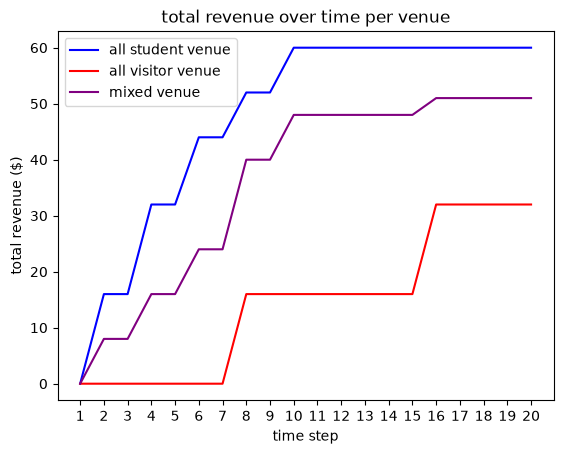

In [9]:
# Put your code here.
import numpy as np
import matplotlib.pyplot as plt


# 1) Build three venues with build_venue: all students, all visitors, and a mixed crowd.
all_student_venue = build_venue(16,0)
all_visitor_venue = build_venue(0,16)
mixed_venue = build_venue(8,8)
# 2) Run each for 20 steps and plot all three histories on ONE labeled plot (with a legend).
rev_history_student = all_student_venue.run(20)
rev_history_visitory = all_visitor_venue.run(20)
rev_history_mixed = mixed_venue.run(20)

time = np.arange(1,21)

plt.plot(time, rev_history_student, color = 'blue', label = 'all student venue')
plt.plot(time, rev_history_visitory, color = 'red', label = 'all visitor venue')
plt.plot(time, rev_history_mixed, color = 'purple', label = 'mixed venue')
plt.xticks(time)
plt.xlabel('time step')
plt.ylabel('total revenue ($)')
plt.title('total revenue over time per venue')
plt.legend()
plt.show()
# In a comment, say which outcome you are tracking and why.
# I am tracking total revenue over time because this would be helpful for the owner of the vending machines to understand
# how quickly they make a profit for any of the venues.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 2.5 (4 points):** In the cell below, **interpret** your results:

* Looking at your Q2.4 plot, how do the **three populations differ**, and what does that tell you about how
  your `Student`s and `Visitor`s behave? (If the three curves came out essentially *identical*, that's a
  sign your subclass difference isn't reaching `step` -- go back and revisit Q2.2.)
* What does the **shape** of a curve (for example, rising and then leveling off) tell you about what is
  happening in the venue over time?
* Name **one** thing you could change about the model (more machines, more frequent restocking, different
  machine placement, customer behavior, ...) that you think would improve the outcome you tracked, and
  briefly say why. Also note **one limitation** of this model as a description of a real venue.

<font size=6 color="#009600">&#9998;</font> 
1) The Student venue consistently brings in higher revenue than the mixed venue, which itself is consistently bringing in more money than the Visitor venue. This tells us that the Students are buying more food than the visitors. There are also more kinks/steps in the student curve than the visitor curve. This tells us that students are also buying more frequently than the visitors / they get hungrier quicker.
2) As the Students curve suggests as it plateaus at the end of the simulation, this may suggest that the students have all run out of money and can no longer purchase anything. This makes sense because the total revenue is capped by the total amount of cash and inventory stocked.
3) One thing we could change about this model is possibly restocking the machines once they are empty. This would be more realistic since most vending machines aren't just left empty, and this would increase the total revenue since we allow for more purchasing opportunities. One way this model is limited compared to a real venue is that most people have snack preferences, so if their preferred snack isn't in one machine, they will avoid purchasing a less-wanted item and instead wait until the find a machine that does stock their preffered item. Since we don't account for preferences here, our model likely overestimates the total revenue since we would expect people to hold off from buying snacks if they're not buying their preffered ones.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 2.6 (5 points):** Now make the model **your own**. Add **one feature** that makes
it more realistic. Some ideas (pick one, or invent your own):

* machines that get **restocked** every few steps,
* customers that **move** between steps,
* machines that occasionally **break** and stop vending,
* **prices that vary** from machine to machine,
* customers with **snack preferences**.

Implement your feature by **subclassing or editing your own classes** (`Customer`, a subclass, or
`Venue`) -- **do not modify the provided `VendingMachine`**. Then **run the model again** and make a short
plot or printout showing the feature's effect. In the markdown cell, **describe the feature you added and
how it changed the results.**

The new revenue history is: [0, 6, 7, 10, 12, 17, 19, 27, 30, 35, 37, 39, 43, 45, 46, 49, 51, 51, 51, 51]
The old revenue history is: [0, 8, 8, 16, 16, 24, 24, 40, 40, 48, 48, 48, 48, 48, 48, 51, 51, 51, 51, 51]


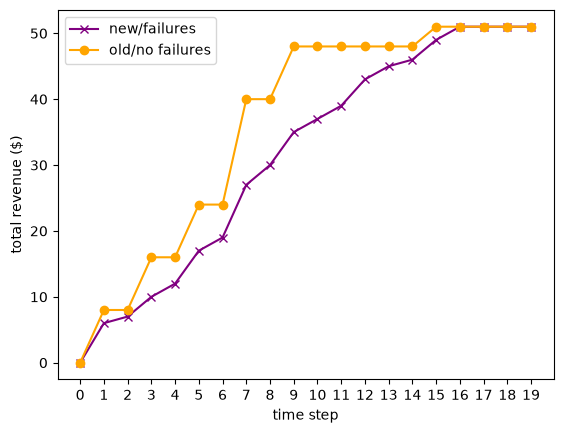

In [10]:
# Put your enhancement here: implement the feature, run the model, and show its effect.
class ImperfectMachine(VendingMachine):
    def __init__(self, starting_treats, location, price = 1, failure_rate = .5):
        self.failure_rate = failure_rate
        super().__init__(starting_treats, location, price)

    def fail(self):
        if random.random() < self.failure_rate:
            return False
        else:
            return True


# redefining the Venue class so that we must check if the machine works before vending.

class Venue:
    def __init__(self, machines, customers):
        self.machines = machines
        self.customers = customers
        self.history = []

    def nearest_machine(self, customer):
        closest_dist = math.inf
        for machine in self.machines:
            distance_to_customer = math.hypot(customer.position[0] - machine.location[0], customer.position[1] - machine.location[1])
            if distance_to_customer < closest_dist:
                closest_dist = distance_to_customer
                closest_machine = machine
        return closest_machine

    def step(self):
        for cust in self.customers:
            cust.get_hungrier()
            if cust.wants_to_buy():
                closest_machine = self.nearest_machine(cust)
                if closest_machine.fail():
                    if closest_machine.inventory:
                        closest_machine.input_cash(closest_machine.price)
                        if closest_machine.make_request(closest_machine.inventory[0]):
                            cust.cash -= closest_machine.price
                            cust.hunger = 0
        
    
        total_revenue = sum(machine.stash for machine in self.machines)
        self.history.append(total_revenue)

    def run(self, n_steps):
        for n in range(n_steps):
            self.step()
        return self.history

#redefining the build venue function so it uses imperfect machines:
import random

SNACKS = ['Twix', 'Snickers', 'M&Ms', 'Chips', 'Pretzels']

def build_venue(n_students, n_visitors, seed=202610):
    """Build a fresh Venue: three freshly-stocked machines plus the requested mix of customers.
    The seed is fixed so customer positions are identical across populations (a fair comparison)."""
    rng = random.Random(seed)
    machines = [ImperfectMachine([s for s in SNACKS for _ in range(4)], location=loc)
                for loc in [(1, 1), (8, 8), (1, 8)]]
    customers  = [Student(position=(rng.randint(0, 9), rng.randint(0, 9))) for _ in range(n_students)]
    customers += [Visitor(position=(rng.randint(0, 9), rng.randint(0, 9))) for _ in range(n_visitors)]
    return Venue(machines, customers)


new_venue = build_venue(8,8)
new_venue_rev_history = new_venue.run(20)
print('The new revenue history is:', new_venue_rev_history)
print('The old revenue history is:', rev_history_mixed)
new_time = np.arange(0,20)

plt.plot(new_time, new_venue_rev_history, marker = 'x', color = 'purple', label = 'new/failures')
plt.plot(new_time, rev_history_mixed, marker = 'o', color = 'orange', label = 'old/no failures')
plt.xticks(new_time)
plt.legend()
plt.xlabel('time step')
plt.ylabel('total revenue ($)')
plt.show()

<font size=6 color="#009600">&#9998;</font> 
- I implemented a potential for failure each time a customer uses the machine. I intended for this to decrease or slow down the rate of total revenue accumulation since some customers wouldn't get to purchase a snack immediately when they wanted.
- This ultimately didn't change results too drastically, however there is a definite decrease in the total revenue from the no failure to failure scenario!

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 2.7 (1 point):** &#128721; **Pause to commit your work.** Save your notebook,
then **add and commit** your changes using a message like `Committing Part 2` (you do not need to push
yet, though you may). This point comes from your commit history showing a commit for Part 2.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---

<a id="part3"></a>
## Part 3: Analyze the machine layout as a graph (40 points)

Your simulation in Part 2 hinted at something the vending-machine operator really cares about:
**where the machines are matters**. The machine nearest a crowd sold out first; a machine off on its own
served an area no one else could reach. But a time-stepped simulation is a lot of machinery just to reason
about **layout**. Sometimes the more useful question isn't "what happens minute by minute?" but simply
**"how are these machines arranged relative to each other across campus?"** -- which ones are clustered and
redundant, which ones stand alone, and how the operator should stock them.

That kind of question is exactly what **graph theory** is good at. So in this part we set the simulation
aside and model the machines as a **graph** (a network): each machine is placed at its approximate
**MSU campus location** and becomes a **node**, and we draw an **edge** between two machines whenever they
are within easy **walking distance** of each other. Turning positions into nodes-and-edges like this is the
same move you made with the cell towers in the Day 11 activity -- and once the layout is a graph, a few
lines of `networkx` can answer questions that would be awkward to get at any other way: *Which machine is
the best-connected hub? Is any machine stranded with no neighbors (an under-served corner of campus)? How
few distinct snack categories do we need so that neighboring machines never duplicate each other?* You'll
answer each of those below.

> &#128161; **Lean on `networkx`.** It's a library built specifically for network data, so most of the
> questions below have a **built-in function or method** -- you rarely need to compute things by hand.
> Keep the [networkx documentation](https://networkx.org/documentation/stable/reference/) open and reach
> for a built-in whenever you can; part of the goal here is to see how much a purpose-built package gives
> you for free.

The positions below are **approximated from the campus map's grid** (`x` runs **west-to-east**, `y` runs
**south-to-north**), and each machine is tagged with a rough campus **`area`**:

- **West:** Brody Hall, 1855 Place, Breslin Center
- **Central:** Spartan Stadium, Wells Hall, Main Library
- **North:** The Union, Broad Art Museum
- **East:** Shaw Hall, and -- way out in the East Neighborhood -- Akers Hall

> &#9888;&#65039; **These are still only rough coordinates, not an accurate map.** They are read off the
> map's grid in arbitrary "campus units" and capture the *relative* layout (roughly who is near whom), but
> they are **not** exact positions, true walking distances, or GPS coordinates -- so please don't use them
> to actually navigate campus!

If you want a visual reference of the campus layout, you can open the [MSU campus map](https://maps.msu.edu/) in a browser and compare the machine locations above to the real buildings.

In [11]:
## DO NOT MODIFY THIS CELL -- approximate MSU campus locations for the vending machines.
# NOTE: positions are read ROUGHLY off the campus map grid (arbitrary "campus units"), NOT an exact map.
# x runs west->east, y runs south->north.   name -> (x, y, area)
machine_locations = {
    'Brody Hall':      (3.25, 7.5, 'West'),
    '1855 Place':      (3.5, 6.35, 'West'),
    'Breslin Center':  (4.0, 6.5, 'West'),
    'Spartan Stadium': (5.75, 6.5, 'Central'),
    'Wells Hall':      (6.25, 6.25, 'Central'),
    'Main Library':    (6.0, 7.25, 'Central'),
    'The Union':       (6.0, 8.5, 'North'),
    'Shaw Hall':       (7.75, 6.0, 'East'),
    'Akers Hall':      (10.25, 5.25, 'East'),
    'Broad Art Museum':(7.5, 8.0, 'North'),
}


<!-- BEGIN QUESTION -->

&#9989; **Question 3.1 (5 points):** Build an **undirected** `networkx` `Graph` from
`machine_locations`:

* Add one node per machine (use the **location name** as the node), storing its `(x, y)` position as a
  node attribute called `pos` (and, if you like, its campus `area`).

* Add an **edge** between any two machines whose straight-line distance is **less than or equal to 2.0**
  (our "walking distance" threshold, in campus units). The straight-line (Euclidean) distance between
  two points $(x_1, y_1)$ and $(x_2, y_2)$ is  $d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$  -- and
  Python's `math.hypot(x2 - x1, y2 - y1)` computes exactly this in one call (remember to `import math`).

Print the number of nodes and edges.

*Hint:* when you add a node, can you attach extra information to it (like its position) at the same time? Check how `add_node` uses extra keyword arguments to accept attributes (e.g. `pos=(x, y)` or `area=area`).

In [40]:
# Put your code for Question 3.1 here.
import networkx as nx
import math

graph = nx.Graph()
for machine in machine_locations.keys():
    graph.add_node(machine, pos = (machine_locations[machine][0], machine_locations[machine][1]), area = machine_locations[machine][2])

for machine in graph.nodes():
    for second_machine in graph.nodes():
        if machine != second_machine:
            distance = math.hypot(graph.nodes[second_machine]['pos'][0] - graph.nodes[machine]['pos'][0],
                graph.nodes[second_machine]['pos'][1] - graph.nodes[machine]['pos'][1])
            if distance <= 2.0:
                graph.add_edge(machine, second_machine)

print('There are', len(graph.nodes()), 'nodes.\nThere are', len(graph.edges()), 'edges')

There are 10 nodes.
There are 11 edges


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.2 (4 points):** Draw the graph using the machines' real positions (use the `pos`
attributes you stored). Give the figure a title.

*Hint:* does `networkx` have a function that draws a graph using a dictionary of node positions? And a helper method that collects a node attribute (you stored `pos`) from a graph object into exactly that kind of dictionary? Look these up in the docs rather than placing the nodes by hand.

Text(0.5, 1.0, 'Walkability between Machines on Campus')

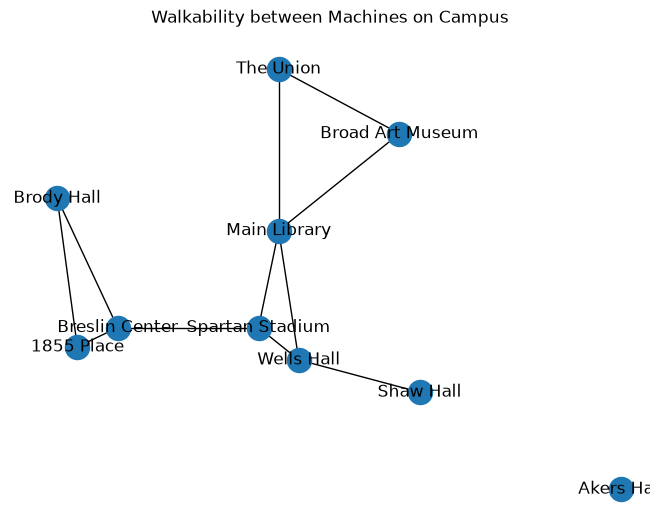

In [47]:
# Put your code for Question 3.2 here.
position_dictionary = nx.get_node_attributes(graph, 'pos')
nx.draw(graph, pos = position_dictionary, with_labels = True)

plt.title('Walkability between Machines on Campus')

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.3 (6 points):** Use your graph to answer the following (print your answers):

* How many machines (nodes) and connections (edges) are there?

* What is the **degree** of each machine, and which machine is the **most connected**?

* **Pick any one machine** and print its **neighbors** (the machines within walking distance of it).

* **Pick any one campus `area`** (`'West'`, `'North'`, `'Central'`, or `'East'`) and create the **induced
  subgraph** of just that area's machines; report how many **nodes** and **edges** it has.

*Hint:* `networkx` almost certainly has a built-in for each of these -- a good habit is to search the docs before writing a loop. Does a graph know how to report its own number of nodes? What about its number of edges? Is there a method to get a single node's degree, or to list its neighbors? And is there a way to pull out the subgraph induced by a chosen set of nodes? Search the [networkx documentation](https://networkx.org/documentation/stable/reference/) for each.

*Building the subgraph:* the induced-subgraph method needs the **list of machine names** in your chosen area. Each machine's area is available in `machine_locations` (the third item in each tuple), and -- if you stored it in Q3.1 -- as a node attribute on the graph as well. Either way, build a list of the names whose area matches your pick, then hand that list to the subgraph method. (If you use the node attributes, check the docs for how to loop over nodes **together with their attribute data**.)

In [86]:
# Put your code for Question 3.3 here.
print('There are', graph.number_of_nodes(), 'machines (nodes) &', graph.size() ,'connections (edges).\n')
print('The degree of each machine is as follows:', graph.degree(), '\nThe most connected machine is', max(graph.degree(), key=lambda pair: pair[1])[0])
print('\nThe Wells Hall machine has the following neighbors:', graph.__getitem__('Wells Hall'))

#building the subgraph:
node_areas = nx.get_node_attributes(graph, 'area')
central_nodes = [node for node in node_areas if node_areas[node] == 'Central']


central_subgraph = graph.subgraph(central_nodes)
print('\nThe Central subgraph has', central_subgraph.number_of_nodes(), 'machines (nodes) &', central_subgraph.size(), 'connections (edges)')

There are 10 machines (nodes) & 11 connections (edges).

The degree of each machine is as follows: [('Brody Hall', 2), ('1855 Place', 2), ('Breslin Center', 3), ('Spartan Stadium', 3), ('Wells Hall', 3), ('Main Library', 4), ('The Union', 2), ('Shaw Hall', 1), ('Akers Hall', 0), ('Broad Art Museum', 2)] 
The most connected machine is Main Library

The Wells Hall machine has the following neighbors: {'Spartan Stadium': {}, 'Main Library': {}, 'Shaw Hall': {}}

The Central subgraph has 3 machines (nodes) & 3 connections (edges)


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.4 (6 points):** The operator wants **adjacent** machines (ones connected by an
edge) to stock **different** snack categories, so nearby machines are not redundant. This is a **graph
coloring** problem -- exactly like the greedy coloring from the Day 11 activity.

* Use `nx.greedy_color` to color the graph, and print the **minimum number of snack categories** this
  coloring needs.

* Then **draw the graph with each machine colored by its assigned category** (use the machine positions,
  as in Q3.2) so you can *see* that no two connected machines share a color.

We need a minimum of 3 snack categories


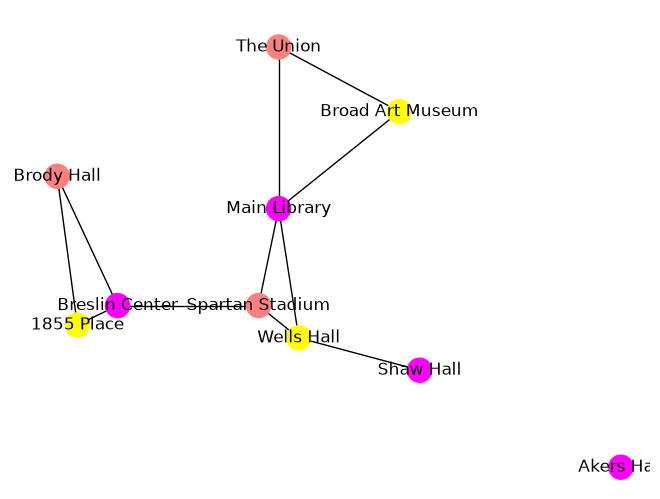

In [99]:
# Put your code for Question 3.4 here.
node_map = nx.greedy_color(graph)

node_colors = list(node_map.values())

print('We need a minimum of', len(set(node_colors)), 'snack categories')
cmap = 'spring'

nx.draw(graph, pos = position_dictionary, node_color = [node_map[node] for node in graph.nodes()], cmap = cmap, with_labels = True)

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.5 (4 points):** The graph you built depends entirely on the **walking-distance
threshold** (you used `2.0`). Rebuild the graph using a **different threshold of your choice** (any value
other than 2.0 -- larger or smaller). Print the new number of edges, and in the markdown cell describe
**how the structure changed**: did more machines become connected? did the isolated machine gain a
neighbor? did the most-connected machine change?

Answer this primarily by **inspecting the graph's properties directly** -- the edge count, the degrees, and which machines are now isolated -- the same way the earlier questions did. You're welcome to **also draw the new graph** if you'd like to *visually confirm* what those properties are telling you, but the drawing is **optional** and should not be your main way of reaching the answer.

In [101]:
# Put your code for Question 3.5 here -- rebuild with your own threshold and print the new edge count.
new_graph = nx.Graph()
for machine in machine_locations.keys():
    new_graph.add_node(machine, pos = (machine_locations[machine][0], machine_locations[machine][1]), area = machine_locations[machine][2])

for machine in new_graph.nodes():
    for second_machine in new_graph.nodes():
        if machine != second_machine:
            distance = math.hypot(new_graph.nodes[second_machine]['pos'][0] - new_graph.nodes[machine]['pos'][0],
                new_graph.nodes[second_machine]['pos'][1] - new_graph.nodes[machine]['pos'][1])
            if distance <= 3.5:
                new_graph.add_edge(machine, second_machine)

print('There are', len(new_graph.nodes()), 'nodes.\nThere are', len(new_graph.edges()), 'edges')
print('The degree of each machine is as follows:', new_graph.degree(), '\nThe most connected machine is', max(new_graph.degree(), key=lambda pair: pair[1])[0])

There are 10 nodes.
There are 31 edges
The degree of each machine is as follows: [('Brody Hall', 6), ('1855 Place', 6), ('Breslin Center', 6), ('Spartan Stadium', 8), ('Wells Hall', 8), ('Main Library', 8), ('The Union', 8), ('Shaw Hall', 6), ('Akers Hall', 1), ('Broad Art Museum', 5)] 
The most connected machine is Spartan Stadium


<font size=6 color="#009600">&#9998;</font>
- Since I increased the walking distance threshold, more machines are considered walkably connected which drastically increased the amount of edges.
- The degree of every node increased, and now all nodes are at least degree 1 (ie: none are completely disconnected!)
- The new most-connected machine is now Spartan Stadium, not the Main Library

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.6 (6 points):** In the cell below, **interpret** the graph analysis (based on the initial threshold of 2.0):

* Is any machine **isolated** (no neighbors)? What does that say about its placement/coverage?
* What does the graph coloring result mean in plain language for how the operator should stock the
  machines?
* Based on your analysis so far, give the operator **one** concrete recommendation about machine
  placement or stocking.

<font size=6 color="#009600">&#9998;</font> 
1) Yes, the Akers machine is completely isolated. This means that it is not walkable from any other machine & is in an under-covered area of campus
2) Since we need 3 colors for the graph, this means that the operator needs 3 types of snacks to avoid redundancy in inventory between neighboring machines
3) The operator should definitely place more machines in the East side of campus because they only have 1 walkable snack option & have no choice besides that.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.7 (8 points):** Your interpretation in Q3.6 probably pointed to a **coverage gap**
(for example, an isolated or under-served machine). Now **act on it.** Choose a **real MSU location** that
does not already have a machine, and add a **new** vending machine there to improve coverage:

* Give your new machine an approximate `(x, y)` position and an `area`, and add it as a node to a **copy**
  of the graph (do not modify the provided `machine_locations` cell).

* Add edges from your new machine to every existing machine within the walking-distance threshold (`2.0`).

* Print your new machine's **degree** and **neighbors**, and check whether the previously **isolated**
  machine (Akers Hall) is now connected.

* **Draw the modified graph** (using the machine positions) so you can *see* your new machine and the
  edges it adds.

*Hint:* work on a **copy** of your graph so you don't disturb the original -- does `networkx` give you a way to copy a graph? Add the new machine and its edges the same way you built the graph in Q3.1 (you can reuse the distance check), then inspect it with the same degree/neighbor methods you found in Q3.3.

Then, in the markdown cell, say **where you put your machine and why**, and whether it improved coverage
(did it reach an under-served area, or just add to an already-crowded cluster?).

The degree of each machine is as follows: [('Brody Hall', 2), ('1855 Place', 2), ('Breslin Center', 3), ('Spartan Stadium', 3), ('Wells Hall', 3), ('Main Library', 4), ('The Union', 2), ('Shaw Hall', 2), ('Akers Hall', 1), ('Broad Art Museum', 2), ('IM East', 2)] 

There are no isolated machines


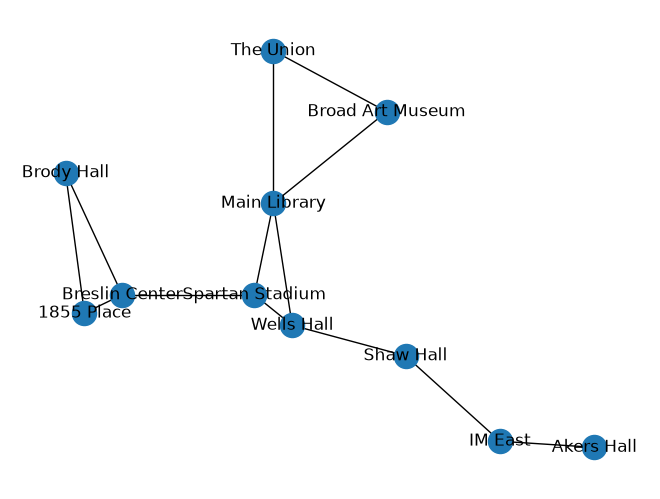

In [123]:
# Put your code for Question 3.6 here -- add your new machine and show how the graph changes.
coverage_graph = graph.copy()
new_node = {
    'IM East' : (9.0, 5.3, 'East')
}
coverage_graph.add_node('IM East', pos = (new_node['IM East'][0], new_node['IM East'][1]), area = new_node['IM East'][2])

for machine in coverage_graph.nodes():
    for second_machine in coverage_graph.nodes():
        if machine != second_machine:
            distance = math.hypot(coverage_graph.nodes[second_machine]['pos'][0] - coverage_graph.nodes[machine]['pos'][0],
                coverage_graph.nodes[second_machine]['pos'][1] - coverage_graph.nodes[machine]['pos'][1])
            if distance <= 2.0:
                coverage_graph.add_edge(machine, second_machine)

print('The degree of each machine is as follows:', coverage_graph.degree(), '\n')

if min(coverage_graph.degree(), key = lambda pair: pair[1])[1] > 0:
    print('There are no isolated machines')
else:
    print('there is at least 1 isolated machine')

cover_position_dictionary = nx.get_node_attributes(coverage_graph, 'pos')
nx.draw(coverage_graph, pos = cover_position_dictionary, with_labels = True)

<font size=6 color="#009600">&#9998;</font> 
- I added a machine at IM East because I saw the the East area had the least amount of machines
- This did improve coverage as Akers & Shaw both gained connections.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 3.8 (1 point):** &#128721; **Pause to commit your work.** Save your notebook,
then **add and commit** your changes using a message like `Committing Part 3` (you do not need to push
yet, though you may). This point comes from your commit history showing a commit for Part 3.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---

<a id="part4"></a>
## Part 4: Reflection and AI/resource audit (10 points)

Now that you've built the model and analyzed the network, take some time to reflect on **how** you got
there -- what you used, how you checked your work, and what you learned. Be candid: there's **no penalty**
for having used AI or other resources, and transparency is part of working professionally. (Course-policy
reminder: AI tools are allowed *with attribution*; **undocumented** AI use is an integrity violation.)

<!-- BEGIN QUESTION -->

&#9989; **Question 4.1 (4 points) -- Resource & AI audit:** Document the outside help you used on this
assignment. For **each** resource you leaned on -- **HiTA or another AI tool**, the
`networkx`/`pandas`/Python **documentation**, your **past assignments**, or **classmates** (within course
policy) -- note:

* which **part/question** you used it for,

* **what** you used (for an AI tool, include the **actual prompt(s)** you gave it), and

* **how you used the result** -- did you take it as-is, modify it, or just use it to understand something?

A short bulleted list or a small table is fine. **If you did not use any outside resources, simply say
so.**

<font size=6 color="#009600">&#9998;</font> 
| Question | Tool | Prompt (if applicable) | How I used the result |
| --- | --- | --- | --- |
| 2.2 | PCA | N/A | relearned the super().__init__() notation & applied to this problem |
| 2.6 | HiTA | 'For 2.6, I want to implement machines that fail sometimes. here is my current code (copied from notebook). how can i define the fail method' , 'how would i use the fail method in the venue class', 'yes i want it to fail permanently. and i want the customer to skip the purchase on the current transaction but they go to the nearest machine on the next one', 'wait what if i want the failure to just be a one off thing', 'with my current code, is failure a one time thing: (copied my code in)', made changes & resent my code to fix the errors it pointed out multiple times, 'AttributeError: 'VendingMachine' object has no attribute 'fail' ', 'TypeError: 'int' object is not subscriptable', 'why is it giving that the revenue history is all 0's' | My overall philosophy about using AI in this class is to harness it as a final check on my work. So, my process starts with my first draft of the code, fixing any errors that I can, then going back and forth with HiTA to debug the errors I don't understand. Most of the time, the fixes it suggests aren't huge structual changes, but small corrections that I will sometimes end up using verbatim or sometimes reinterpret in a way that makes more sense to me|
| 3.1 | HiTA | 'is this what 3.1 is looking for: # Put your code for Question 3.1 here. import networkx as nx graph = nx.Graph() for machine in machine_locations: graph.add_node(machine, pos = (machine[0], machine[1]), area = machine[2]) ' , 'why does it give me a name error that pos is not defined', 'does this get the correct coordinates for the node creation: graph = nx.Graph() for machine in machine_locations.keys(): graph.add_node(machine, pos = (machine_locations[machine][0], machine_locations[machine][1]), area = machine_locations[machine][2])', | None of these prompts returned a specific line of code to implement, so I mainly used these as a tool to understand why my code was throwing errors & implemented the general fixes it suggested. |
| 3.3 | HiTA | 'for 3.3, how do i print the label of the node with the most connections not the degree: print('The degree of each machine is as follows:', graph.degree(), '\nThe most connected machine is', max(node[1] for node in graph.degree())) ', (after it suggested to 'maximize by the pair’s second item, then print its first item.') i asked 'how do i do that', 'how do i use the neighbors function in networkx? im not sure how to use the iterator it outputs', 'invalid synatax: central_nodes = node_areas[for i in node areas][node_areas[i][1] == 'Central'] ', 'central_nodes = node_areas[node for node in node_areas if node['area'] == 'Central'] ', (after it suggested fixes to my list comprehension, i asked:) 'so how would i do that', 'how can i harness builtin networkx functions to accomlish 3.3: node_areas = nx.get_node_attributes(graph, 'area') central_nodes = [] for node in node_areas.keys(): if node_areas[node][1] == 'Central': central_nodes.append(node) central_subgraph = graph.subgraph(central_nodes) nx.draw(central_subgraph) ', 'how would i use list comphrension', 'what would the thing to collect be ', 'central_nodes = [node for i in node_areas if node_areas[node] == 'Central'] ? ' | More of the responses it gave for this debugging session were used as-is because I was working more with individual lines to answer the specific questions posedc in 3.3. However, a lot of this was also just trying to understand how to use list comphrehension to accomplish these tasks in as efficiently as possible. |
| 3.4 | HiTA | 'there are same colored connected nodes, how do i fix this: # Put your code for Question 3.4 here. node_map = nx.greedy_color(graph) print(node_map) node_colors = list(node_map.values()) print('We need a minimum of', len(set(node_colors)), 'snack categories') cmap = 'spring' nx.draw(graph, pos = position_dictionary, node_color = node_colors, cmap = cmap, with_labels = True) ', 'how do i look up each nodes color in the draw ', copied my code for revision | It didn't give me anything to plop straight into my working code, so this was more to understand how exactly the functions called on the node map & whatnot. |

## <!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 4.2 (2 points) -- Verifying your work:** Pick **two** of your answers from this
assignment -- ideally **one from Part 2** (the ABM) and **one from Part 3** (the graph) -- and for each,
explain **how you know it is correct**. Point to something concrete: a test cell that passed, a value you
computed by hand and compared, a plot whose shape matched what you expected, or a graph property you
cross-checked (e.g., the number of edges, or that a machine you thought was isolated really has degree 0).
If you are *not* sure an answer is right, explain how you *would* check it.

<font size=6 color="#009600">&#9998;</font> 
1) 2.3: I know that I constructed the Venue class correctly because the test cell passed with no errors.
2) 3.4: I know that my answer, that we only need 3 unique snacks to avoid redundancy, is correct because the colored network graph is successfully colored with only 3 colors so that no two neighboring machines have the same color, and we only have 3 colors on the graph.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 4.3 (3 points) -- Reflecting on your process:** In a few sentences each:

* **(1 pt)** Where did an outside resource or AI tool **genuinely help** you, and where did you rely mostly
  on **your own understanding**?

* **(1 pt)** Which half was more challenging for you -- **building the agent-based model (Part 2)** or
  **analyzing the graph (Part 3)** -- and **why**?

* **(1 pt)** This assignment leaned on purpose-built libraries (`networkx`, `pandas`). Name **one thing you
  now understand better** about using a library designed for a job versus writing everything yourself from
  scratch.

<font size=6 color="#009600">&#9998;</font>
1) I genuinely learned a lot from using AI, specifically HiTA, to get a better grasp on list comprehension especially. Since we haven't explicitly learned this in class, instead using loops to achieve the same end goal, I am better able to read and write code using list comprehension now! I mostly relied on my own understanding when building the general structure of my answers / planning how to tackle a big problem.
2) Building the ABM was more challenging for me because conceptually it was harder to visualize what was going on behind the scenes in terms of how the agents worked together during the simulation.
3) Particularly when we were analyzing the characteristics of the machine network in Part 3, I got a better sense of what kinds of questions built-in functions can typically help you answer- quantifiable aspects of a dataset or network, in this case. More often than not, if you have a simple question about the size or general shape of your data, there is likely a built-in that can help you answer that quickly rather than you overthinking it and writing your own code to answer the same question.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

&#9989; **Question 4.4 (1 point):** &#128721; **Final commit and push.** Save your notebook, then
**add, commit, and push** your completed assignment to GitHub. This point comes from your final commit
being pushed to your `cmse202-f26-turnin` repository.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---
## Assignment wrap-up

Congratulations, you're done! Make sure you have **saved, committed, and pushed** your final notebook to
your `cmse202-f26-turnin` repository, and submit this assignment by uploading it to the course **GradeScope** page, which you can find by using the dropdown menu on the right side of the navigation bar in D2L. Look for **"Homework 02 - Student Notebook Submission"** assignment and upload your Jupyter Notebook there -- once it uploads, double-check that you submitted the version with your completed solutions! You should also get a confirmation that a PDF version of your submission was successfully built. We will grade the PDF version.

For the full step-by-step process, see the [Gradescope Submission Instructions](https://msu-cmse-courses.github.io/cmse202-Fall2026/course_materials/CMSE202_GradescopeSubmissionInstructions.html) on the course website. **It is important that you complete "Step 3" of the process and tag your solutions to each specific question of the assignment outline.**

&#169; Copyright 2026, Department of Computational Mathematics, Science and Engineering at Michigan State University